Topic: practicing linear regression on boston House pricing dataset.
steps:
1.   import dataset
2.   importing dependencies
3.   build dataframes
4.   extract features and divide them into dependent,independent
5.   split the data
6.   standardizing
7.   implementing LR
8.   cross validation
9.   prediction
10.  graph

In [64]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [65]:
df=fetch_california_housing()

In [66]:
dataset=pd.DataFrame(df.data)

In [67]:
dataset.columns=df.feature_names

In [68]:
dataset.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [69]:
X=dataset
y=df.target

In [70]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.30,random_state=42)

In [71]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)
#fit(): When you call fit() on X_train, the StandardScaler (or any other preprocessor) learns the parameters from your training data. For StandardScaler, this means it calculates the mean and standard deviation for each feature in X_train.
#transform(): Immediately after learning, transform() then applies these learned mean and standard deviation values to X_train to scale it. This results in X_train having a mean of 0 and a standard deviation of 1 for each feature.
#When you call transform() on X_test, the StandardScaler does not re-calculate the mean and standard deviation. Instead, it uses the mean and standard deviation that it learned from X_train during the fit() step.
#It then applies these previously learned scaling parameters to X_test.

In [72]:
from sklearn.linear_model import LinearRegression
regression= LinearRegression()
regression.fit(X_train,y_train)

LinearRegression()

In [73]:
from sklearn.model_selection import cross_val_score
mse=cross_val_score(regression,X_train,y_train,scoring='neg_mean_squared_error',cv=10)

In [74]:
np.mean(mse)

np.float64(-0.5257104326777)

In [75]:
pred=regression.predict(X_train)

In [76]:
pred

array([2.13761366, 1.76385736, 2.75114302, ..., 2.03900584, 2.84130506,
       2.27916759])

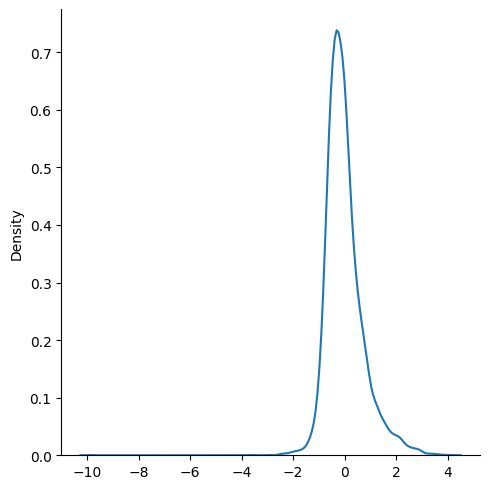

In [77]:
import seaborn as sns
# Make predictions on the test set
y_pred = regression.predict(X_test)
# Calculate residuals (actual - predicted) for the test set
residuals = y_test - y_pred
# Plot the distribution of these residuals
sns.displot(residuals, kind='kde')

### What is R-squared (R2) Score?

The R-squared score, also known as the coefficient of determination, is a statistical measure that represents the proportion of the variance in the dependent variable that can be explained by the independent variables in a regression model. In simpler terms:

*   It tells you how well your model's predictions fit the actual data points.
*   It ranges from 0 to 1 (or sometimes negative, though ideally it should be positive).
    *   **R2 = 1**: Indicates that the model explains all the variability of the response data around its mean. This is an ideal, but rarely achievable, scenario in real-world data.
    *   **R2 = 0**: Indicates that the model explains no variability of the response data around its mean. This means your model is no better than simply predicting the mean of the target variable for every input.
    *   **R2 < 0**: Can occur if the model fits the data worse than a horizontal line (i.e., worse than simply predicting the mean). This usually suggests a very poor model or incorrect application.


In [78]:
r2_score = regression.score(X_test, y_test)
print(f"R2 Score on the test set: {r2_score}")

R2 Score on the test set: 0.5957702326061664
